# 06. Sori Estimation via Reduced Sampling

Counting the exact number of sori in every row of a frond is labor-intensive, especially when scaling the analysis to more individuals. `03_spatial_distribution_imputation` already defined 5 reference points along the fertile zone (base, Q1, center, Q3, apex) to study distribution shape, and although no robust correlation was found between these points and morphometric variables, the information in their position and magnitude is still useful for a different purpose: approximating an individual's total sori count using only these 5 points, instead of every row.

This works because the 5 points are not isolated measurements, they are samples of a continuous sori-density curve along the frond. Under this framing, estimating total sori count becomes a numerical integration problem: approximating the area under the sori-density curve (i.e., the total count) from a reduced number of sampled points. This notebook tests two classic numerical integration methods, Simpson's rule and the trapezoidal rule, validating each against the real row-by-row counts of the 23 individuals with complete data, to evaluate whether counting only 5 strategic rows, instead of the typical 60-100, allows a reasonably accurate estimate for future individuals.

## 1. Import Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
plt.rcdefaults()


## 2. Load Data

We load the row-level dataset from `03_spatial_distribution_imputation`, which includes all 24 individuals (23 real, 1 imputed for H15). We separate out the 23 real individuals, since only they have a true total sori count to validate the estimation methods against.

In [11]:
df_sori_imputed = pd.read_csv("../data/processed/sori_imputed.csv")
df_sori_real = df_sori_imputed[df_sori_imputed["is_imputed"] == False].reset_index(drop=True)

print(f"df_sori_imputed: {df_sori_imputed.shape[0]} rows ({df_sori_imputed['individual_id'].nunique()} individuals)")
print(f"df_sori_real: {df_sori_real.shape[0]} rows ({df_sori_real['individual_id'].nunique()} individuals)")

df_sori_imputed: 1921 rows (24 individuals)
df_sori_real: 1835 rows (23 individuals)


## 3. Recomputing the 5 Characteristic Points

We recompute the same 5 characteristic points defined in `03_spatial_distribution_imputation` (Section 5),  base, Q1, center, Q3, apex,  this time only for the 23 real individuals, since these are the points that will be used both to estimate and to validate total sori count against their true values.

In [12]:
df_sori_real = df_sori_real.copy()
df_sori_real["n_rows_total"] = df_sori_real.groupby("individual_id")["row_id"].transform("max")
df_sori_real["relative_position"] = df_sori_real["row_id"] / df_sori_real["n_rows_total"]


def extract_five_points(group):
    group = group.sort_values("row_id", ascending=True).reset_index(drop=True)
    with_sori = group[group["n_sori_per_row"] > 0]

    idx_start = with_sori.index.min()
    idx_end = with_sori.index.max()
    fertile_zone = group.loc[idx_start:idx_end].reset_index(drop=True)
    n_fertile_rows = len(fertile_zone)

    five_indices = np.linspace(0, n_fertile_rows - 1, 5).round().astype(int)
    positions = fertile_zone.loc[five_indices, "relative_position"].values
    values = fertile_zone.loc[five_indices, "n_sori_per_row"].values

    return pd.Series({
        "base_pos": positions[0], "sori_base": values[0],
        "q1_pos": positions[1], "sori_q1": values[1],
        "center_pos": positions[2], "sori_center": values[2],
        "q3_pos": positions[3], "sori_q3": values[3],
        "apex_pos": positions[4], "sori_apex": values[4],
        "n_fertile_rows": n_fertile_rows,
        "n_rows_total": group["n_rows_total"].iloc[0],
        "total_real": group["n_sori_per_row"].sum(),
    })


df_shape_points = (
    df_sori_real.groupby("individual_id")
    .apply(extract_five_points, include_groups=False)
    .reset_index()
)

df_shape_points.round(3)

,individual_id,base_pos,sori_base,q1_pos,sori_q1,center_pos,sori_center,q3_pos,sori_q3,apex_pos,sori_apex,n_fertile_rows,n_rows_total,total_real
0,H01,0.128,12.0,0.256,52.0,0.384,54.0,0.512,22.0,0.640,4.0,45.0,86.0,1656.0
1,H02,0.237,36.0,0.424,50.0,0.610,36.0,0.780,26.0,0.966,4.0,44.0,59.0,1554.0
2,H03,0.262,28.0,0.412,48.0,0.562,52.0,0.700,12.0,0.850,4.0,48.0,80.0,1728.0
3,H04,0.202,16.0,0.348,52.0,0.494,40.0,0.652,14.0,0.798,6.0,54.0,89.0,1826.0
4,H05,0.256,30.0,0.402,40.0,0.537,48.0,0.671,22.0,0.817,6.0,47.0,82.0,1456.0
5,H06,0.294,18.0,0.424,30.0,0.553,42.0,0.694,28.0,0.824,2.0,46.0,85.0,1290.0
6,H07,0.242,32.0,0.374,46.0,0.505,38.0,0.648,16.0,0.780,2.0,50.0,91.0,1590.0
7,H08,0.395,2.0,0.494,34.0,0.593,24.0,0.679,18.0,0.778,4.0,32.0,81.0,644.0
8,H09,0.405,10.0,0.554,52.0,0.703,42.0,0.838,12.0,0.986,4.0,44.0,74.0,1296.0
9,H10,0.161,18.0,0.355,46.0,0.548,32.0,0.726,26.0,0.919,4.0,48.0,62.0,1464.0


## 4. Visual Check: Is the Distribution Shape Suitable for Simpson's Rule?

Before applying Simpson's rule, we visualize the sori-distribution shape for all 23 individuals with real data, confirming that most show a relatively smooth unimodal pattern, a favorable condition for the parabolic approximation to capture the real curve well, in contrast to more erratic shapes or multiple peaks, where Simpson's rule would perform poorly. The 5 characteristic points (red) are overlaid on each curve to visualize how well they sample its shape.

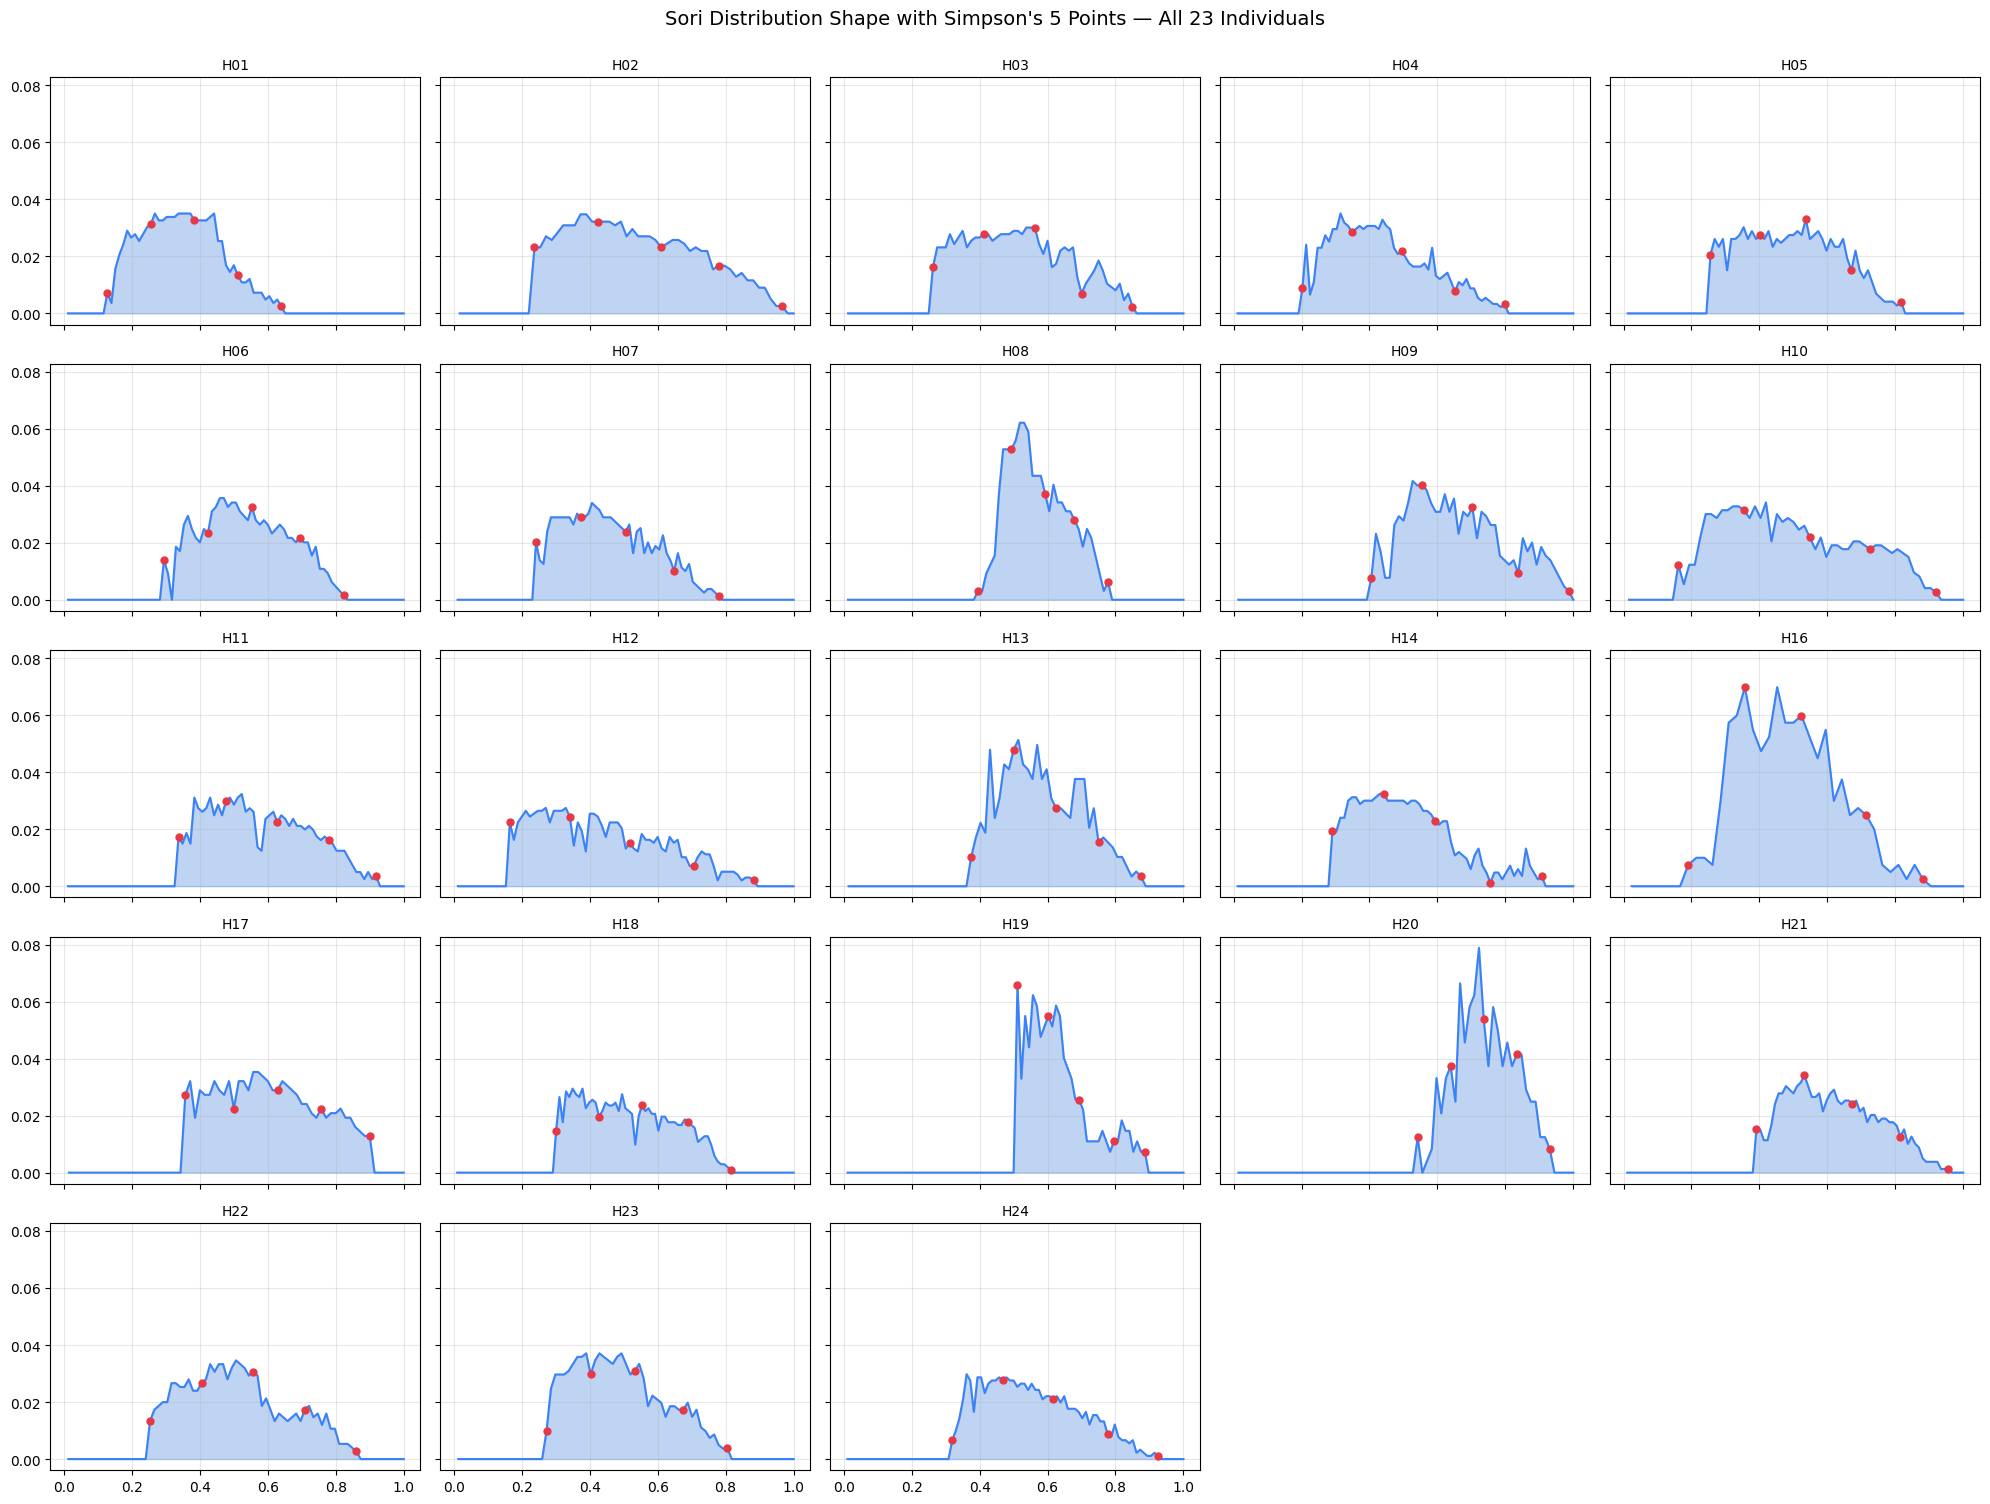

In [13]:
ids = sorted(df_sori_real["individual_id"].unique())

n_cols = 5
n_rows = int(np.ceil(len(ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for i, ind in enumerate(ids):
    group = df_sori_real[df_sori_real["individual_id"] == ind].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = group["n_sori_per_row"].sum()
    n_rows_total = group["row_id"].max()
    rel_pos = group["row_id"] / n_rows_total
    density = group["n_sori_per_row"] / total

    axes[i].plot(rel_pos, density, color="#3b82f6", lw=1.5)
    axes[i].fill_between(rel_pos, density, alpha=0.3, color="#2d73d4")

    points_row = df_shape_points[df_shape_points["individual_id"] == ind].iloc[0]
    points_x = [points_row["base_pos"], points_row["q1_pos"], points_row["center_pos"],
                points_row["q3_pos"], points_row["apex_pos"]]
    points_y_abs = [points_row["sori_base"], points_row["sori_q1"], points_row["sori_center"],
                     points_row["sori_q3"], points_row["sori_apex"]]
    points_y = [y / total for y in points_y_abs]

    axes[i].scatter(points_x, points_y, color="#e63946", s=25, zorder=3)
    axes[i].set_title(ind, fontsize=10)
    axes[i].grid(alpha=0.3)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Sori Distribution Shape with Simpson's 5 Points — All 23 Individuals", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

Most individuals (H01-H07, H09-H12, H14, H17, H18, H21-H24) show a wide, plateau-like distribution with a single gentle bump, a favorable shape for Simpson's rule, since the parabolic segments between consecutive points can reasonably approximate this kind of curve. A smaller group (H08, H13, H16, H19, H20) instead shows sharp, narrow peaks, H16 in particular shows multiple jagged peaks rather than a single one. These narrower, more concentrated distributions are expected to be harder for a 5-point parabolic approximation to capture accurately, tested formally in the next section.

## 5. Estimating Total Sori via Simpson's Rule

### 5.1 Method

Simpson's 1/3 composite rule approximates the area under a curve using two parabolic segments, one fit through base/Q1/center, another through center/Q3/apex. Applied here, it estimates the average sori count per fertile row as a weighted combination of the 5 points, then multiplies by the number of fertile rows to get the total: `total ≈ N · (n_b + 4·n_q1 + 2·n_c + 4·n_q3 + n_a) / 12`, where N is the number of fertile rows.

### 5.2 Validation

In [14]:
df_shape_points["sori_estimated_simpson"] = (
    (df_shape_points["sori_base"] + 4*df_shape_points["sori_q1"] + 2*df_shape_points["sori_center"] +
     4*df_shape_points["sori_q3"] + df_shape_points["sori_apex"]) / 12
) * df_shape_points["n_fertile_rows"]

df_shape_points["error_pct_simpson"] = (
    (df_shape_points["sori_estimated_simpson"] - df_shape_points["total_real"]).abs() / df_shape_points["total_real"] * 100
).round(1)

print(f"Mean error:   {df_shape_points['error_pct_simpson'].mean():.1f}%")
print(f"Median error: {df_shape_points['error_pct_simpson'].median():.1f}%")
print(f"Max error:    {df_shape_points['error_pct_simpson'].max():.1f}% (individual: {df_shape_points.loc[df_shape_points['error_pct_simpson'].idxmax(), 'individual_id']})")

df_shape_points.sort_values("error_pct_simpson", ascending=False)[["individual_id", "n_fertile_rows", "total_real", "sori_estimated_simpson", "error_pct_simpson"]]

Mean error:   6.9%
Median error: 6.2%
Max error:    27.2% (individual: H16)


,individual_id,n_fertile_rows,total_real,sori_estimated_simpson,error_pct_simpson
14,H16,30.0,802.0,1020.000000,27.2
2,H03,48.0,1728.0,1504.000000,13.0
19,H21,53.0,1582.0,1757.833333,11.1
17,H19,34.0,546.0,600.666667,10.0
15,H17,39.0,1246.0,1124.500000,9.8
3,H04,54.0,1826.0,1647.000000,9.8
13,H14,54.0,1666.0,1521.000000,8.7
7,H08,32.0,644.0,698.666667,8.5
21,H23,42.0,1618.0,1491.000000,7.8
18,H20,29.0,482.0,517.166667,7.3


Simpson's rule yields an average relative error of 6.9% (median 6.2%), with H16 as the clear worst case (27.2%), consistent with the visual check in Section 4, where H16 stood out for its multiple jagged peaks rather than a single smooth bump. H03 and H21 follow as the next largest errors (13.0% and 11.1%), both also flagged earlier as having sharper, narrower peaks. Most individuals fall well below 10% error, suggesting the method is reasonably reliable for the majority of shapes present in this sample.

### 5.3 Error vs. Curve Roughness

To explore whether curve irregularity explains Simpson's error, we compute a roughness metric (sum of absolute differences between consecutive fertile rows, normalized by total sori) and correlate it with each individual's percentage error.

In [15]:
def compute_roughness(group):
    group = group.sort_values("row_id", ascending=True).reset_index(drop=True)
    with_sori = group[group["n_sori_per_row"] > 0]
    idx_start = with_sori.index.min()
    idx_end = with_sori.index.max()
    fertile_zone = group.loc[idx_start:idx_end]

    values = fertile_zone["n_sori_per_row"].values
    diffs = np.abs(np.diff(values))
    return diffs.sum() / values.sum()


df_shape_points["curve_roughness"] = (
    df_sori_real.groupby("individual_id")
    .apply(compute_roughness, include_groups=False)
    .reset_index(drop=True)
)

rho, p = spearmanr(df_shape_points["curve_roughness"], df_shape_points["error_pct_simpson"])
print(f"Spearman rho = {rho:.3f}, p = {p:.3f}")


Spearman rho = -0.012, p = 0.955


No meaningful correlation is found between curve roughness and Simpson's error (Spearman rho = -0.012, p = 0.955), a rough, jagged curve is not inherently harder to approximate than a smooth one. This suggests the error depends more on the overall position and shape of the peak (e.g., how narrow or off-center it is) than on row-to-row fluctuation, consistent with H16's error stemming from multiple peaks rather than local noise.

## 6. Estimating Total Sori via the Trapezoidal Rule

Having ruled out curve roughness as the driver of Simpson's error, we compare it against a simpler reference method: the trapezoidal rule, which approximates the curve between the 5 points with straight segments instead of parabolas, a larger simplification, but potentially more stable for curves with sharp peaks that parabolas can overshoot.

In [16]:
df_shape_points["sori_estimated_trapezoid"] = (
    (df_shape_points["sori_base"]/2 + df_shape_points["sori_q1"] + df_shape_points["sori_center"] +
     df_shape_points["sori_q3"] + df_shape_points["sori_apex"]/2) / 4
) * df_shape_points["n_fertile_rows"]

df_shape_points["error_pct_trapezoid"] = (
    (df_shape_points["sori_estimated_trapezoid"] - df_shape_points["total_real"]).abs() / df_shape_points["total_real"] * 100
).round(1)

print(f"Mean error:   {df_shape_points['error_pct_trapezoid'].mean():.1f}%")
print(f"Median error: {df_shape_points['error_pct_trapezoid'].median():.1f}%")
print(f"Max error:    {df_shape_points['error_pct_trapezoid'].max():.1f}%")

Mean error:   7.3%
Median error: 7.6%
Max error:    19.7%


The trapezoidal rule yields a slightly higher average error (7.3% vs. 6.9%) but a notably lower worst-case error (19.7% vs. 27.2%, both on H16), consistent with the hypothesis that straight-line segments are less prone to overshooting sharp, narrow peaks than parabolas.

## 7. Simpson vs. Trapezoidal: Comparison

In [17]:
df_shape_points["better_method"] = np.where(
    df_shape_points["error_pct_simpson"] < df_shape_points["error_pct_trapezoid"], "Simpson", "Trapezoid"
)

print(df_shape_points["better_method"].value_counts())
df_shape_points[["individual_id", "error_pct_simpson", "error_pct_trapezoid", "better_method"]].sort_values("error_pct_simpson", ascending=False)

better_method
Simpson      13
Trapezoid    10
Name: count, dtype: int64


,individual_id,error_pct_simpson,error_pct_trapezoid,better_method
14,H16,27.2,19.7,Trapezoid
2,H03,13.0,11.1,Trapezoid
19,H21,11.1,4.7,Trapezoid
17,H19,10.0,9.0,Trapezoid
15,H17,9.8,8.4,Trapezoid
3,H04,9.8,13.5,Simpson
13,H14,8.7,8.4,Trapezoid
7,H08,8.5,1.9,Trapezoid
21,H23,7.8,11.1,Simpson
18,H20,7.3,3.8,Trapezoid


Simpson performs better on more individuals overall (13 of 23 vs. 10 for Trapezoid), consistent with its lower average error. However, neither method dominates uniformly, Trapezoid wins specifically on the individuals with the sharpest peaks (H16, H03, H21, H19, H17, H14, H08, H20, H11, H22), where Simpson's parabolic segments tend to overshoot. This complementary pattern is what motivates testing a hybrid approach next.

To complement the numerical comparison above, we visualize each individual's real distribution curve alongside both estimation methods: the Trapezoidal rule (straight lines between the 5 points) and Simpson's rule (parabolic segments), with each method's error percentage shown in the subplot title.

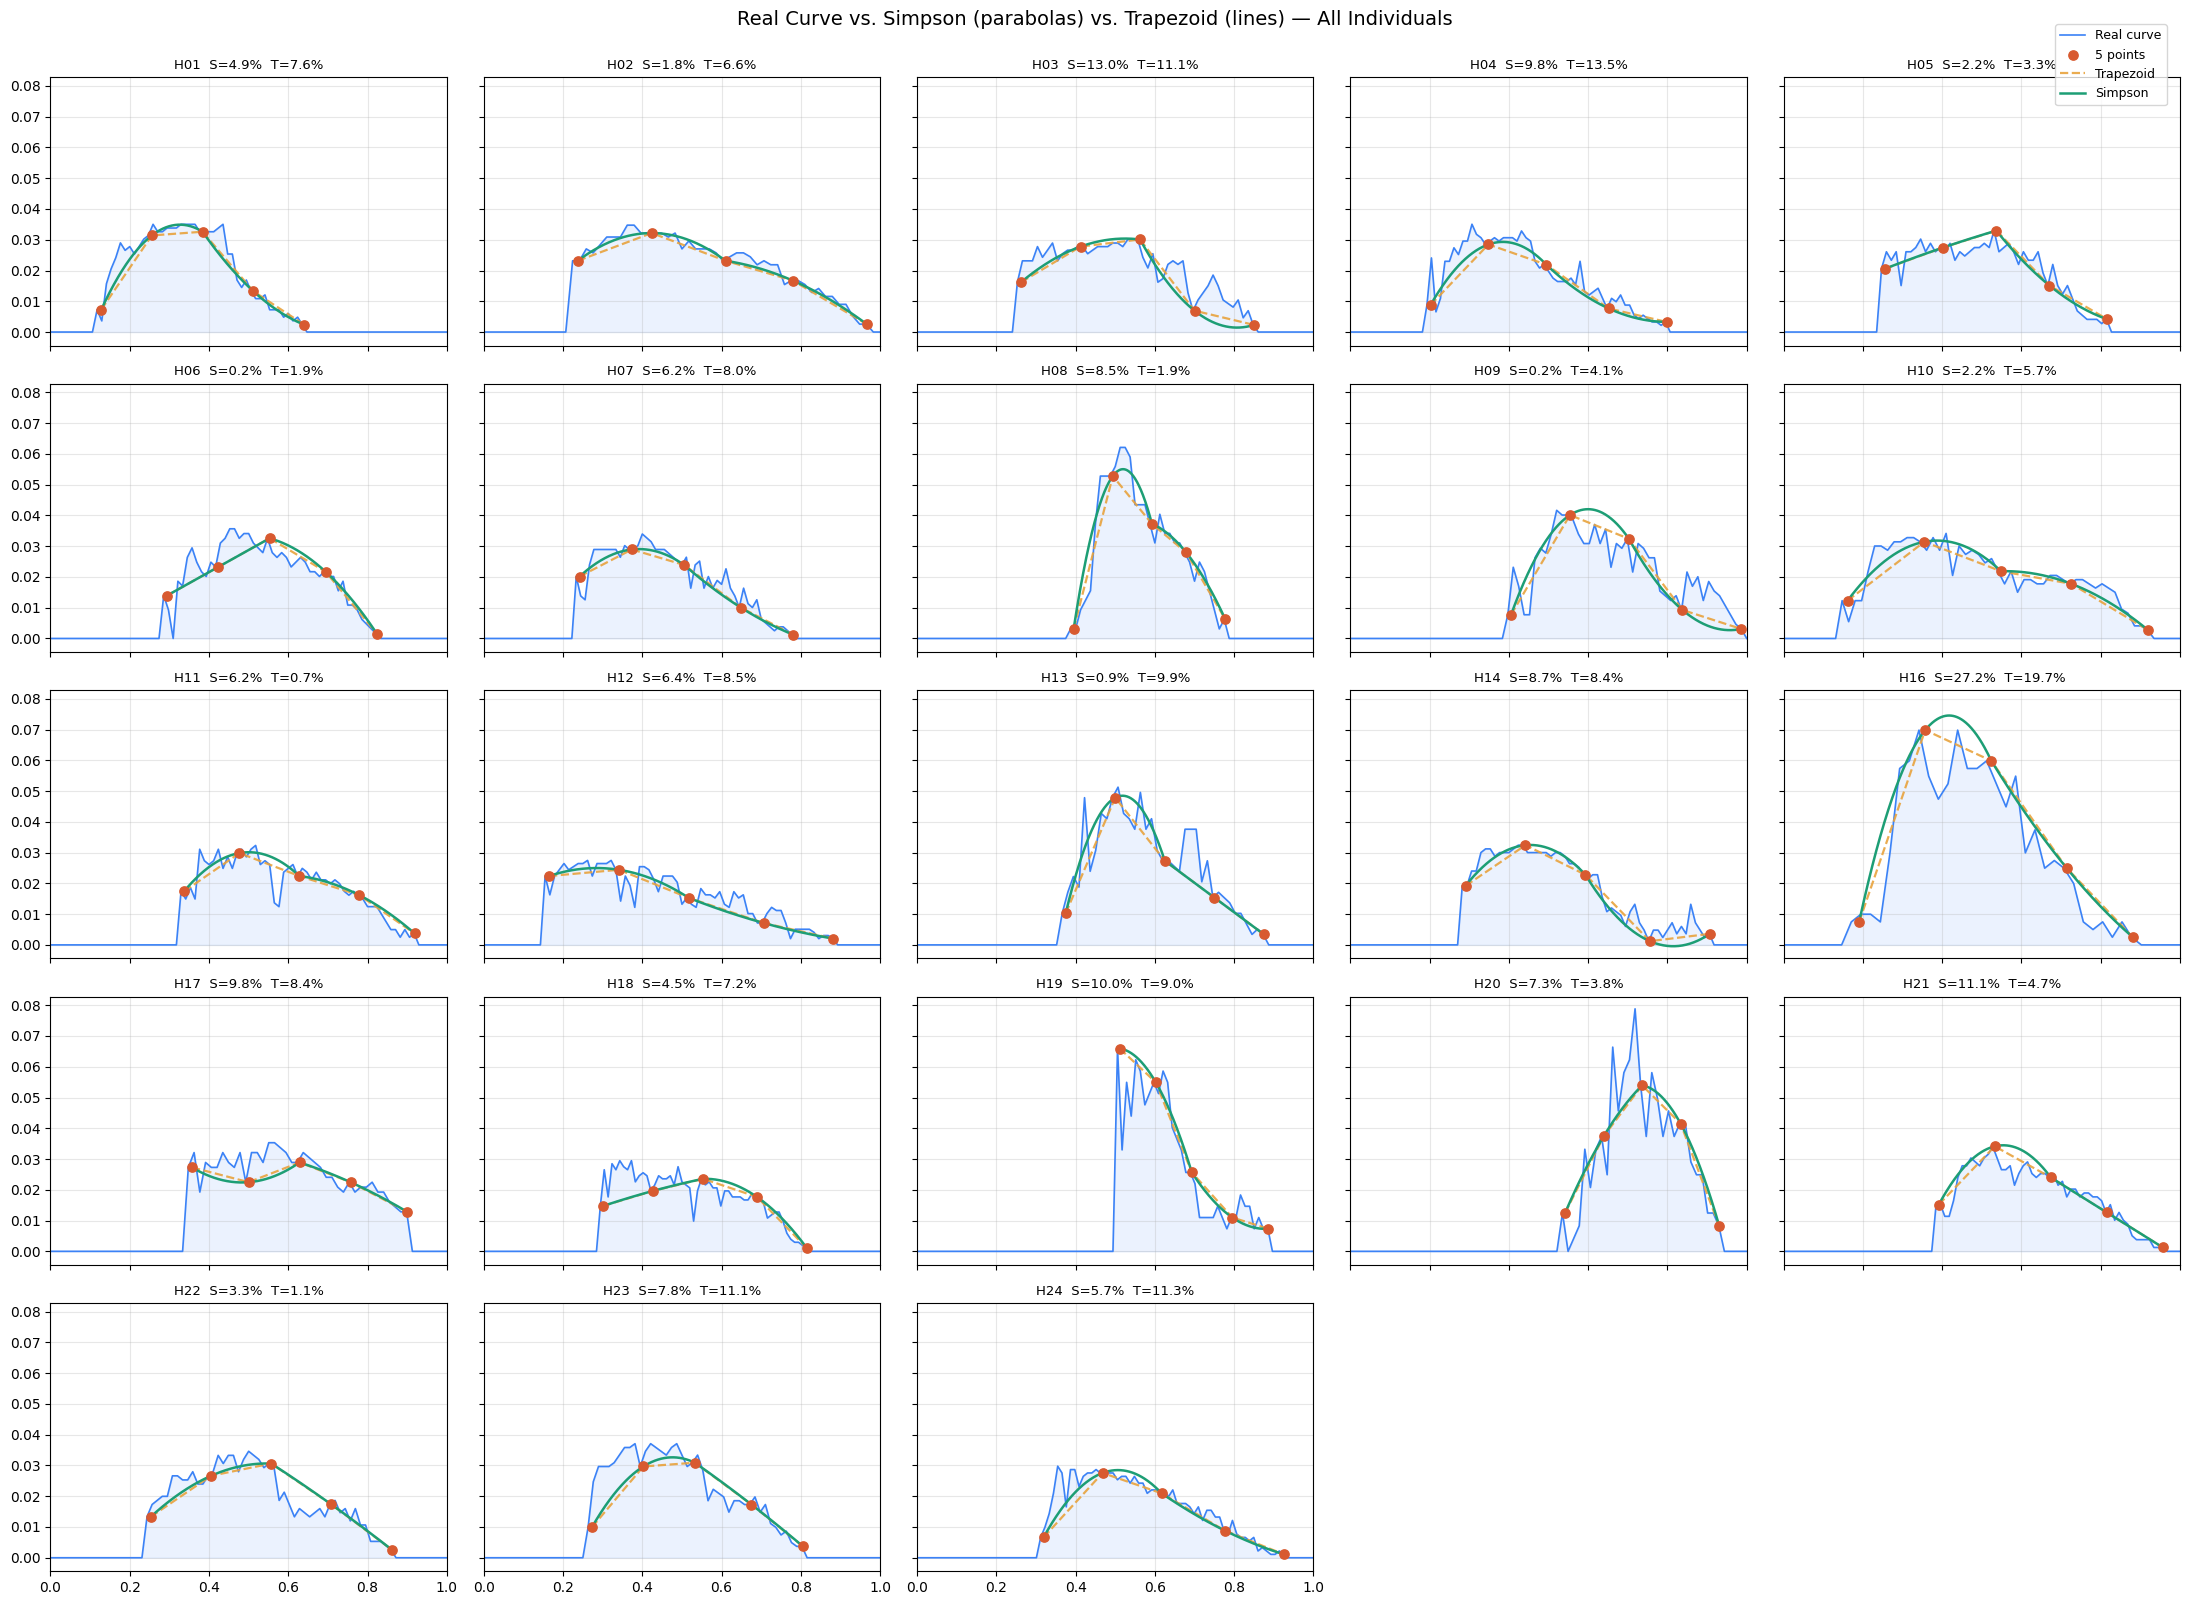

In [18]:
ids = sorted(df_sori_real["individual_id"].unique())

n_cols = 5
n_rows = int(np.ceil(len(ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 3.2 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for i, ind in enumerate(ids):
    group = df_sori_real[df_sori_real["individual_id"] == ind].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = group["n_sori_per_row"].sum()
    proportion = group["n_sori_per_row"] / total
    x_real = np.linspace(0, 1, len(group))

    points_row = df_shape_points[df_shape_points["individual_id"] == ind].iloc[0]
    x5 = np.array([points_row["base_pos"], points_row["q1_pos"], points_row["center_pos"],
                   points_row["q3_pos"], points_row["apex_pos"]])
    y5_abs = np.array([points_row["sori_base"], points_row["sori_q1"], points_row["sori_center"],
                        points_row["sori_q3"], points_row["sori_apex"]])
    y5 = y5_abs / total

    error_simpson = points_row["error_pct_simpson"]
    error_trapezoid = points_row["error_pct_trapezoid"]

    coef1 = np.polyfit(x5[:3], y5[:3], 2)
    coef2 = np.polyfit(x5[2:], y5[2:], 2)
    xs1 = np.linspace(x5[0], x5[2], 200)
    xs2 = np.linspace(x5[2], x5[4], 200)
    ys1 = np.polyval(coef1, xs1)
    ys2 = np.polyval(coef2, xs2)

    axes[i].plot(x_real, proportion, color="#3b82f6", lw=1.2, label="Real curve")
    axes[i].fill_between(x_real, proportion, alpha=0.10, color="#3b82f6")

    axes[i].scatter(x5, y5, color="#D85A30", s=45, zorder=5, label="5 points")

    axes[i].plot(x5, y5, "--", color="#E8A33D", lw=1.6, alpha=0.9, label="Trapezoid")

    axes[i].plot(xs1, ys1, color="#1D9E75", lw=1.8, label="Simpson")
    axes[i].plot(xs2, ys2, color="#1D9E75", lw=1.8)

    axes[i].set_title(f"{ind}  S={error_simpson:.1f}%  T={error_trapezoid:.1f}%", fontsize=9.5)
    axes[i].grid(alpha=0.3)
    axes[i].set_xlim(0, 1)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.99, 0.995), fontsize=9)

fig.suptitle("Real Curve vs. Simpson (parabolas) vs. Trapezoid (lines) — All Individuals", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/06_simpson_vs_trapezoid.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Hybrid Approach

Since neither method fully dominates the other, Simpson offers better average precision, Trapezoid is more stable against sharp peaks like H16's, we test a third approach: averaging both estimates. The logic is that if Simpson's and Trapezoid's errors are not perfectly correlated, averaging them could cancel out some of each method's individual mistakes.

In [19]:
df_shape_points["sori_estimated_hybrid"] = (df_shape_points["sori_estimated_simpson"] + df_shape_points["sori_estimated_trapezoid"]) / 2
df_shape_points["error_pct_hybrid"] = (
    (df_shape_points["sori_estimated_hybrid"] - df_shape_points["total_real"]).abs() / df_shape_points["total_real"] * 100
).round(1)

print(f"Simpson   - mean: {df_shape_points['error_pct_simpson'].mean():.1f}%, median: {df_shape_points['error_pct_simpson'].median():.1f}%, max: {df_shape_points['error_pct_simpson'].max():.1f}%")
print(f"Trapezoid - mean: {df_shape_points['error_pct_trapezoid'].mean():.1f}%, median: {df_shape_points['error_pct_trapezoid'].median():.1f}%, max: {df_shape_points['error_pct_trapezoid'].max():.1f}%")
print(f"Hybrid    - mean: {df_shape_points['error_pct_hybrid'].mean():.1f}%, median: {df_shape_points['error_pct_hybrid'].median():.1f}%, max: {df_shape_points['error_pct_hybrid'].max():.1f}%")

Simpson   - mean: 6.9%, median: 6.2%, max: 27.2%
Trapezoid - mean: 7.3%, median: 7.6%, max: 19.7%
Hybrid    - mean: 6.9%, median: 6.2%, max: 23.4%


Averaging both estimates preserves Simpson's average and median performance (6.9% / 6.2%) while reducing its worst-case error from 27.2% to 23.4% on H16, confirming that the two methods' errors are not perfectly correlated, so combining them cancels out part of each one's individual mistakes. The hybrid does not match Trapezoid's worst-case stability (19.7%), but offers the best overall balance between average accuracy and resistance to the method's main failure mode (sharp, narrow peaks).

## 9. Final Results and Formula

In [20]:
df_sori_estimation_results = df_shape_points[["individual_id", "n_fertile_rows", "total_real", "sori_estimated_hybrid", "error_pct_hybrid"]] \
    .sort_values("error_pct_hybrid", ascending=False).reset_index(drop=True)
df_sori_estimation_results["sori_estimated_hybrid"] = df_sori_estimation_results["sori_estimated_hybrid"].round().astype(int)
df_sori_estimation_results

,individual_id,n_fertile_rows,total_real,sori_estimated_hybrid,error_pct_hybrid
0,H16,30.0,802.0,990,23.4
1,H03,48.0,1728.0,1520,12.0
2,H04,54.0,1826.0,1613,11.7
3,H19,34.0,546.0,598,9.5
4,H23,42.0,1618.0,1465,9.5
5,H17,39.0,1246.0,1133,9.1
6,H14,54.0,1666.0,1523,8.6
7,H24,58.0,1814.0,1660,8.5
8,H21,53.0,1582.0,1707,7.9
9,H12,62.0,1966.0,1819,7.5


Based on the analysis above, the total sori count of an individual can be estimated from just 5 sampled rows along the fertile zone using the hybrid formula:

**total ≈ N · [Simpson(n_b, n_q1, n_c, n_q3, n_a) + Trapezoid(n_b, n_q1, n_c, n_q3, n_a)] / 2**

where N is the number of fertile rows, and n_b, n_q1, n_c, n_q3, n_a are the sori counts at the base, first quartile, center, third quartile, and apex of the fertile zone. This allows estimating total sori by counting only 5 strategic rows instead of the typical 60-100, at the cost of a median error around 6-7%.

## 10. Export

In [12]:
df_sori_estimation_results.to_csv("../data/processed/sori_estimation_validation.csv", index=False)
print(f"df_sori_estimation_results exported: {df_sori_estimation_results.shape[0]} rows × {df_sori_estimation_results.shape[1]} columns")

df_sori_estimation_results exported: 23 rows × 5 columns
